# Hand-sign recognition with multi-scale CNNs

Do parallel convolution branches help on the SIGNS images from ML4HD?

I implement a compact Inception-style model in PyTorch and compare it with LeNet. This keeps the multi-scale idea from the Inception laboratory while reducing the model enough for a CPU run. It is not the full Inception-v4 architecture.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from sklearn.metrics import classification_report, confusion_matrix

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    Trainer,
    TrainConfig,
    classification_scores,
    image_grid,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "06_signs_and_inception"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## SIGNS data

The official training HDF5 is split into training and validation subsets. The provided test HDF5 keeps its role as the final test set. Pixel scaling uses the known 8-bit range; channel order is converted from NHWC to NCHW.

torch.Size([864, 3, 64, 64]) [144, 144, 144, 144, 144, 144]


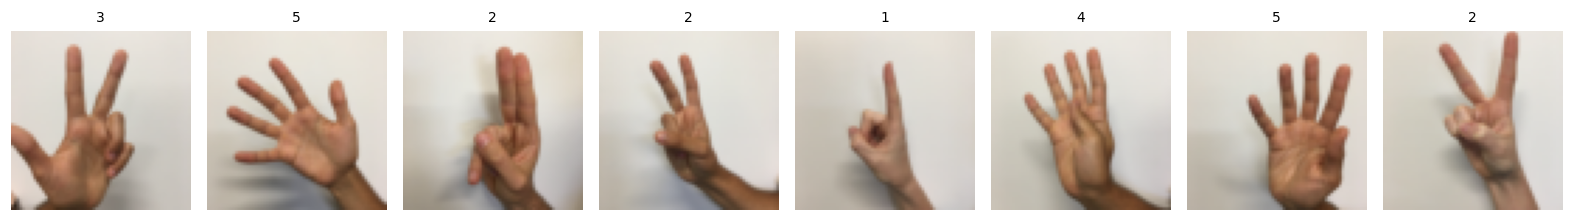

In [5]:
from vision_projects.data import signs_data
from vision_projects.models import InceptionBlock, InceptionCNN, LeNet

data = signs_data(root / "data")
train_loader, validation_loader, test_loader = data.loaders(32)
images, labels = data.train.tensors
print(images.shape, torch.bincount(labels).tolist())
image_grid(images[:8], output / "signs.png", labels[:8].tolist())

## Parallel receptive fields

The block concatenates pointwise, 3 by 3, 5 by 5 and pooled features along the channel dimension. Pointwise bottlenecks reduce expensive spatial convolution. Padding keeps each branch at the same spatial size.

In [7]:
print(inspect.getsource(InceptionBlock))
block = InceptionBlock(16)
probe = block(torch.randn(2, 16, 16, 16))
assert probe.shape == (2, 32, 16, 16)
print(inspect.getsource(InceptionCNN))

class InceptionBlock(nn.Module):
    def __init__(self, channels, width=8):
        super().__init__()
        self.pointwise = nn.Sequential(nn.Conv2d(channels, width, 1), nn.ReLU())
        self.local = nn.Sequential(
            nn.Conv2d(channels, width, 1), nn.ReLU(), nn.Conv2d(width, width, 3, padding=1), nn.ReLU()
        )
        self.wide = nn.Sequential(
            nn.Conv2d(channels, width, 1), nn.ReLU(), nn.Conv2d(width, width, 5, padding=2), nn.ReLU()
        )
        self.pooled = nn.Sequential(
            nn.AvgPool2d(3, stride=1, padding=1), nn.Conv2d(channels, width, 1), nn.ReLU()
        )

    def forward(self, features):
        return torch.cat(
            [self.pointwise(features), self.local(features), self.wide(features), self.pooled(features)],
            dim=1,
        )

class InceptionCNN(nn.Module):
    def __init__(self, channels=3, classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(channels, 16, 3, st

## Equal-budget comparison

Each network receives the same training identities and minibatch order. Learning rate and epochs are fixed before final testing. I select the architecture on validation NLL, because an overconfident wrong answer has a larger loss.

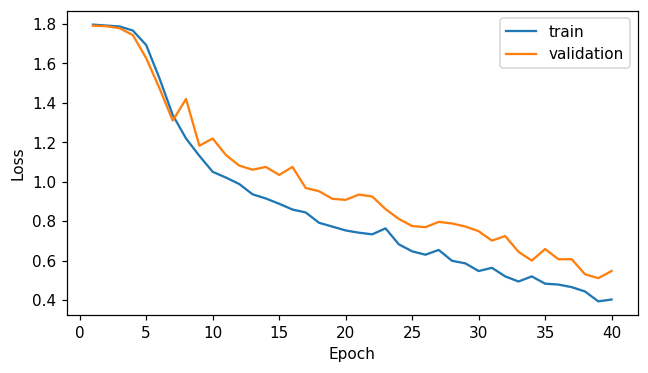

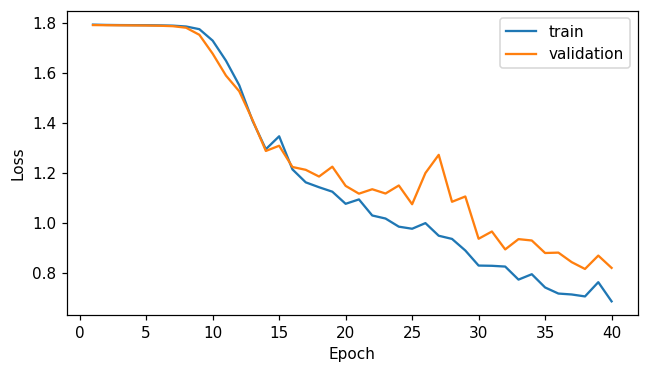

       model  parameters  accuracy  macro_f1       nll
0      lenet       27982  0.814815  0.810966  0.511313
1  inception        7206  0.712963  0.710485  0.815549


In [9]:
rows, trained = [], {}
for name, constructor in [
    ("lenet", lambda: LeNet(channels=3, classes=6)),
    ("inception", InceptionCNN),
]:
    seed_everything()
    model = constructor()
    train_loader, validation_loader, test_loader = data.loaders(32)
    history = Trainer(
        model, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS, learning_rate=0.001)
    ).fit(train_loader, validation_loader)
    plot_history(history, output / f"{name}_loss.png")
    logits, targets = predict(model, validation_loader)
    rows.append(
        {
            "model": name,
            "parameters": sum(p.numel() for p in model.parameters()),
            **classification_scores(logits, targets),
        }
    )
    trained[name] = model
print(pd.DataFrame(rows))
selected = min(rows, key=lambda row: row["nll"])["model"]
model = trained[selected]

## Held-out errors

The test set is evaluated after validation has selected weights. The confusion matrix keeps the true class on the vertical axis. Mistakes with high confidence deserve inspection because cross-entropy and accuracy respond differently to them.

{'accuracy': 0.85, 'macro_f1': 0.8467739530811027, 'nll': 0.5004514937283282}
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        20
           1       0.83      0.95      0.88        20
           2       1.00      0.65      0.79        20
           3       0.71      1.00      0.83        20
           4       0.93      0.65      0.76        20
           5       0.79      0.95      0.86        20

    accuracy                           0.85       120
   macro avg       0.88      0.85      0.85       120
weighted avg       0.88      0.85      0.85       120



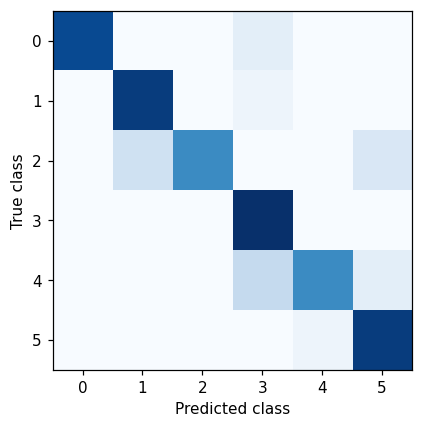

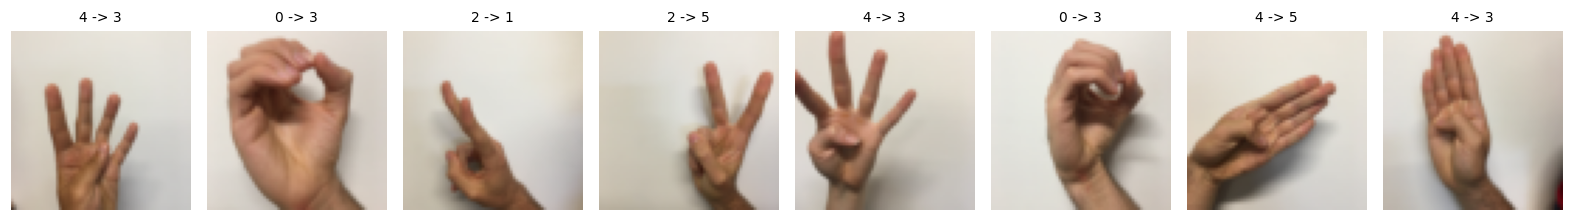

In [11]:
logits, targets = predict(model, test_loader)
scores = classification_scores(logits, targets)
print(scores)
print(classification_report(targets, logits.argmax(-1), zero_division=0))
fig, axis = plt.subplots(figsize=(5, 4))
matrix = confusion_matrix(targets, logits.argmax(-1))
axis.imshow(matrix, cmap="Blues")
axis.set(xlabel="Predicted class", ylabel="True class")
fig.tight_layout()
fig.savefig(output / "confusion.png", dpi=140)
plt.show()
mistakes = torch.where(logits.argmax(-1) != targets)[0]
if len(mistakes):
    mistake_ids = mistakes[:8]
    image_grid(
        data.test.tensors[0][mistake_ids],
        output / "errors.png",
        [f"{int(targets[i])} -> {int(logits[i].argmax())}" for i in mistake_ids],
    )

## First-layer activations

Feature maps are activations for one input, so they depend on its appearance. Displaying them alongside the image helps distinguish filter weights from image-specific responses. The figure uses the selected model's first convolution.

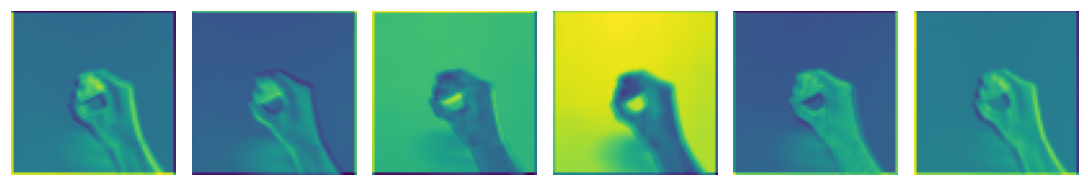

In [13]:
with torch.inference_mode():
    maps = model.features[0](data.test.tensors[0][:1])
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for axis, feature in zip(axes, maps[0, :6]):
    axis.imshow(feature.numpy(), cmap="viridis")
    axis.axis("off")
fig.tight_layout()
fig.savefig(output / "feature_maps.png", dpi=140)
plt.show()
results = {
    "validation": rows,
    "selected_model": selected,
    "test": scores,
    "train_images": len(data.train),
}

## Reading the result

A small SIGNS test set gives noisy per-class estimates. The multi-scale model should be judged alongside parameter count and the training curves. Six short epochs may leave either architecture undertrained.

Recorded run: With 40 epochs, validation selected LeNet and its official SIGNS test accuracy was 85.0%. The compact Inception model used fewer parameters but had higher validation NLL in this run. The experiment shows the cost of a small multi-scale representation on this training set.

In [15]:
result_path = root / "results" / "06_signs_and_inception.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/06_signs_and_inception.json


## Next experiment

Add factorized 5 by 5 branches, measure elapsed training time and repeat over several seeds. Keep the HDF5 test split fixed throughout.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). [Inception-v4](https://arxiv.org/abs/1602.07261).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.